In [1]:
# Import necessary libraries
import optuna
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load the Pima Indian Diabetes dataset from sklearn
# Note: Scikit-learn's built-in 'load_diabetes' is a regression dataset.
# We will load the actual diabetes dataset from an external source
import pandas as pd

# Load the Pima Indian Diabetes dataset (from UCI repository)
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI',
           'DiabetesPedigreeFunction', 'Age', 'Outcome']

# Load the dataset
df = pd.read_csv(url, names=columns)

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
import numpy as np

# Replace zero values with NaN in columns where zero is not a valid value
cols_with_missing_vals = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_missing_vals] = df[cols_with_missing_vals].replace(0, np.nan)

# Impute the missing values with the mean of the respective column
df.fillna(df.mean(), inplace=True)

# Check if there are any remaining missing values
print(df.isnull().sum())


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [5]:
# Split into features (X) and target (y)
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Split data into training and test sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Optional: Scale the data for better model performance
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Check the shape of the data
print(f'Training set shape: {X_train.shape}')
print(f'Test set shape: {X_test.shape}')


Training set shape: (537, 8)
Test set shape: (231, 8)


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Define the objective function
def objective(trial):
    # Suggest values for the hyperparameters
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 3, 20)

    # Create the RandomForestClassifier with suggested hyperparameters
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        random_state=42
    )

    # Perform 3-fold cross-validation and calculate accuracy
    score = cross_val_score(model, X_train, y_train, cv=3, scoring='accuracy').mean()

    return score  # Return the accuracy score for Optuna to maximize


In [7]:
# Create a study object and optimize the objective function
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler())  # We aim to maximize accuracy
study.optimize(objective, n_trials=50)  # Run 50 trials to find the best hyperparameters

[I 2026-11-01 17:02:05,234] A new study created in memory with name: no-name-fa7c7549-e63a-4e64-bb34-add093f119bd
[I 2026-11-01 17:02:07,339] Trial 0 finished with value: 0.7783985102420856 and parameters: {'n_estimators': 130, 'max_depth': 18}. Best is trial 0 with value: 0.7783985102420856.
[I 2026-11-01 17:02:09,980] Trial 1 finished with value: 0.7746741154562384 and parameters: {'n_estimators': 165, 'max_depth': 7}. Best is trial 0 with value: 0.7783985102420856.
[I 2026-11-01 17:02:12,436] Trial 2 finished with value: 0.7597765363128491 and parameters: {'n_estimators': 152, 'max_depth': 9}. Best is trial 0 with value: 0.7783985102420856.
[I 2026-11-01 17:02:14,751] Trial 3 finished with value: 0.7746741154562384 and parameters: {'n_estimators': 135, 'max_depth': 16}. Best is trial 0 with value: 0.7783985102420856.
[I 2026-11-01 17:02:16,636] Trial 4 finished with value: 0.7635009310986964 and parameters: {'n_estimators': 121, 'max_depth': 4}. Best is trial 0 with value: 0.7783985

In [8]:
# Print the best result
print(f'Best trial accuracy: {study.best_trial.value}')
print(f'Best hyperparameters: {study.best_trial.params}')

Best trial accuracy: 0.7821229050279329
Best hyperparameters: {'n_estimators': 125, 'max_depth': 18}


## Samplers in Optuna

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Define the objective function
def objective(trial):
    # Suggest values for the hyperparameters
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 3, 20)

    # Create the RandomForestClassifier with suggested hyperparameters
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        random_state=42
    )

    # Perform 3-fold cross-validation and calculate accuracy
    score = cross_val_score(model, X_train, y_train, cv=3, scoring='accuracy').mean()

    return score  # Return the accuracy score for Optuna to maximize


In [10]:
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.RandomSampler())  # We aim to maximize accuracy
study.optimize(objective, n_trials=50)  # Run 50 trials to find the best hyperparameters

[I 2026-11-01 17:17:22,745] A new study created in memory with name: no-name-8a9d9920-e285-4f10-b3a9-4231713273c3
[I 2026-11-01 17:17:24,536] Trial 0 finished with value: 0.7616387337057727 and parameters: {'n_estimators': 116, 'max_depth': 4}. Best is trial 0 with value: 0.7616387337057727.
[I 2026-11-01 17:17:26,363] Trial 1 finished with value: 0.7653631284916201 and parameters: {'n_estimators': 109, 'max_depth': 13}. Best is trial 1 with value: 0.7653631284916201.
[I 2026-11-01 17:17:27,569] Trial 2 finished with value: 0.7597765363128491 and parameters: {'n_estimators': 69, 'max_depth': 6}. Best is trial 1 with value: 0.7653631284916201.
[I 2026-11-01 17:17:28,562] Trial 3 finished with value: 0.7746741154562384 and parameters: {'n_estimators': 54, 'max_depth': 18}. Best is trial 3 with value: 0.7746741154562384.
[I 2026-11-01 17:17:32,006] Trial 4 finished with value: 0.7709497206703911 and parameters: {'n_estimators': 190, 'max_depth': 14}. Best is trial 3 with value: 0.77467411

In [11]:
# Print the best result
print(f'Best trial accuracy: {study.best_trial.value}')
print(f'Best hyperparameters: {study.best_trial.params}')

Best trial accuracy: 0.7802607076350093
Best hyperparameters: {'n_estimators': 196, 'max_depth': 19}


In [12]:
from sklearn.metrics import accuracy_score

# Train a RandomForestClassifier using the best hyperparameters from Optuna
best_model = RandomForestClassifier(**study.best_trial.params, random_state=42)

# Fit the model to the training data
best_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = best_model.predict(X_test)

# Calculate the accuracy on the test set
test_accuracy = accuracy_score(y_test, y_pred)

# Print the test accuracy
print(f'Test Accuracy with best hyperparameters: {test_accuracy:.2f}')


Test Accuracy with best hyperparameters: 0.74


In [14]:
search_space = {
    'n_estimators': [50, 100, 150, 200],
    'max_depth': [5, 10, 15, 20]
}

In [15]:
# Create a study and optimize it using GridSampler
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.GridSampler(search_space))
study.optimize(objective)

[I 2026-11-01 17:21:37,554] A new study created in memory with name: no-name-4f9b53c7-a724-49e3-a8e4-9ac2a3567753
[I 2026-11-01 17:21:39,091] Trial 0 finished with value: 0.7690875232774674 and parameters: {'n_estimators': 100, 'max_depth': 5}. Best is trial 0 with value: 0.7690875232774674.
[I 2026-11-01 17:21:41,675] Trial 1 finished with value: 0.7672253258845437 and parameters: {'n_estimators': 150, 'max_depth': 10}. Best is trial 0 with value: 0.7690875232774674.
[I 2026-11-01 17:21:42,630] Trial 2 finished with value: 0.7728119180633147 and parameters: {'n_estimators': 50, 'max_depth': 15}. Best is trial 2 with value: 0.7728119180633147.
[I 2026-11-01 17:21:44,472] Trial 3 finished with value: 0.7653631284916201 and parameters: {'n_estimators': 100, 'max_depth': 15}. Best is trial 2 with value: 0.7728119180633147.
[I 2026-11-01 17:21:46,281] Trial 4 finished with value: 0.7690875232774674 and parameters: {'n_estimators': 100, 'max_depth': 20}. Best is trial 2 with value: 0.772811

In [16]:
# Print the best result
print(f'Best trial accuracy: {study.best_trial.value}')
print(f'Best hyperparameters: {study.best_trial.params}')

Best trial accuracy: 0.7746741154562384
Best hyperparameters: {'n_estimators': 50, 'max_depth': 5}


In [17]:
from sklearn.metrics import accuracy_score

# Train a RandomForestClassifier using the best hyperparameters from Optuna
best_model = RandomForestClassifier(**study.best_trial.params, random_state=42)

# Fit the model to the training data
best_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = best_model.predict(X_test)

# Calculate the accuracy on the test set
test_accuracy = accuracy_score(y_test, y_pred)

# Print the test accuracy
print(f'Test Accuracy with best hyperparameters: {test_accuracy:.2f}')

Test Accuracy with best hyperparameters: 0.74


## Optuna Visualizations

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Define the objective function
def objective(trial):
    # Suggest values for the hyperparameters
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 3, 20)

    # Create the RandomForestClassifier with suggested hyperparameters
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        random_state=42
    )

    # Perform 3-fold cross-validation and calculate accuracy
    score = cross_val_score(model, X_train, y_train, cv=3, scoring='accuracy').mean()

    return score  # Return the accuracy score for Optuna to maximize


In [23]:
# Create a study object and optimize the objective function
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler())  # We aim to maximize accuracy
study.optimize(objective, n_trials=50)  # Run 50 trials to find the best hyperparameters


[I 2026-11-01 17:27:12,877] A new study created in memory with name: no-name-3a894bfe-667b-45ae-905d-494806ed8f21
[I 2026-11-01 17:27:14,523] Trial 0 finished with value: 0.7709497206703911 and parameters: {'n_estimators': 99, 'max_depth': 12}. Best is trial 0 with value: 0.7709497206703911.
[I 2026-11-01 17:27:17,400] Trial 1 finished with value: 0.7709497206703911 and parameters: {'n_estimators': 166, 'max_depth': 15}. Best is trial 0 with value: 0.7709497206703911.
[I 2026-11-01 17:27:18,764] Trial 2 finished with value: 0.7653631284916201 and parameters: {'n_estimators': 72, 'max_depth': 15}. Best is trial 0 with value: 0.7709497206703911.
[I 2026-11-01 17:27:21,171] Trial 3 finished with value: 0.7616387337057727 and parameters: {'n_estimators': 145, 'max_depth': 4}. Best is trial 0 with value: 0.7709497206703911.
[I 2026-11-01 17:27:23,293] Trial 4 finished with value: 0.7579143389199254 and parameters: {'n_estimators': 136, 'max_depth': 3}. Best is trial 0 with value: 0.77094972

In [18]:
# For visualizations
from optuna.visualization import plot_optimization_history, plot_parallel_coordinate, plot_slice, plot_contour, plot_param_importances

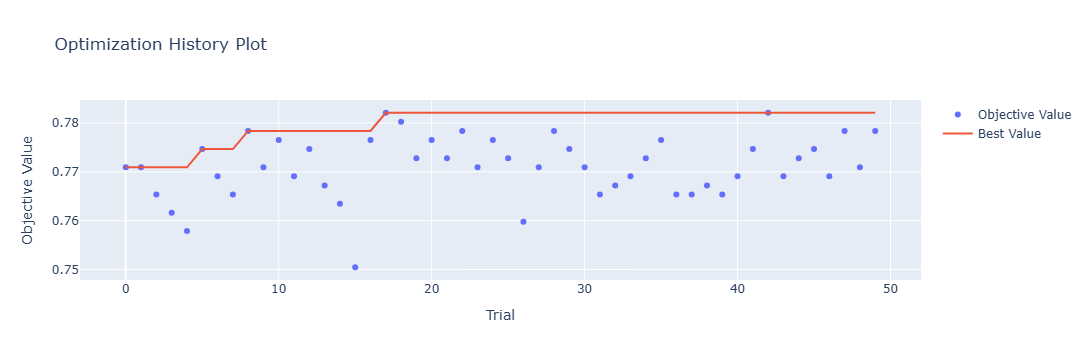

In [24]:
# 1. Optimization History
plot_optimization_history(study).show()

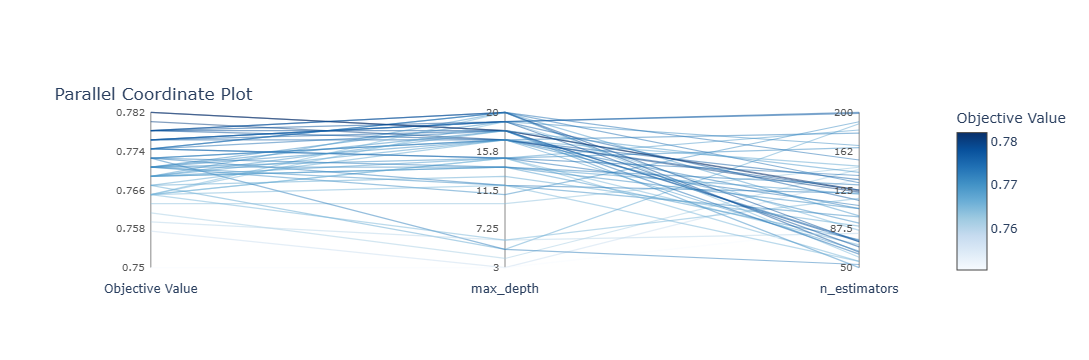

In [26]:
# 2. Parallel Coordinates Plot
plot_parallel_coordinate(study).show()

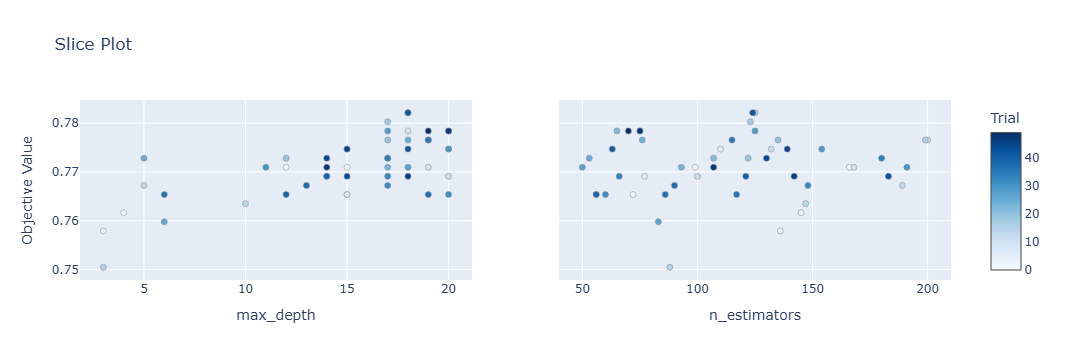

In [27]:
# 3. Slice Plot
plot_slice(study).show()

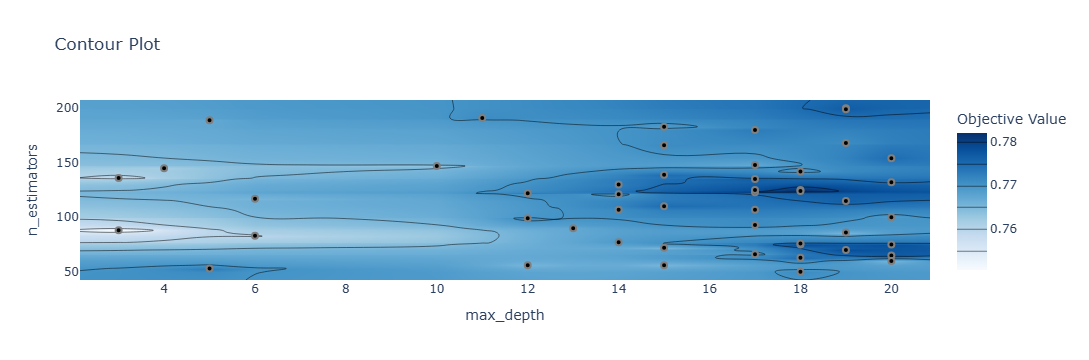

In [28]:
# 4. Contour Plot
plot_contour(study).show()

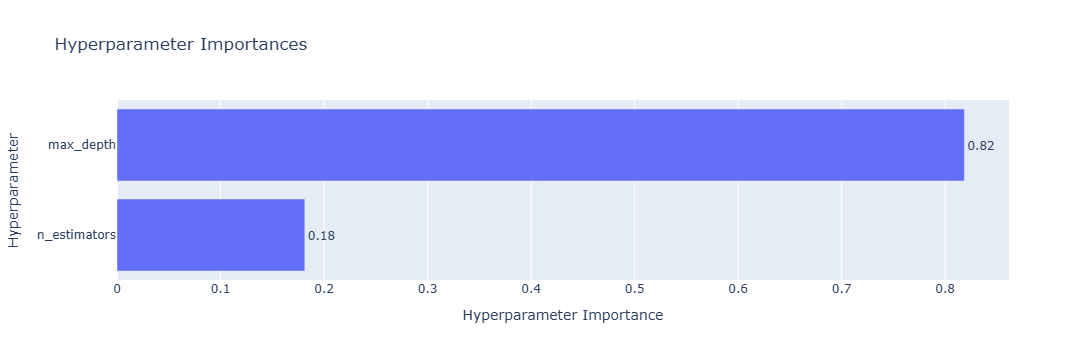

In [29]:
# 5. Hyperparameter Importance
plot_param_importances(study).show()

## Optimizing Multiple ML Models

In [30]:
# Importing the required libraries
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

In [31]:
# Define the objective function for Optuna
def objective(trial):
    # Choose the algorithm to tune
    classifier_name = trial.suggest_categorical('classifier', ['SVM', 'RandomForest', 'GradientBoosting'])

    if classifier_name == 'SVM':
        # SVM hyperparameters
        c = trial.suggest_float('C', 0.1, 100, log=True)
        kernel = trial.suggest_categorical('kernel', ['linear', 'rbf', 'poly', 'sigmoid'])
        gamma = trial.suggest_categorical('gamma', ['scale', 'auto'])

        model = SVC(C=c, kernel=kernel, gamma=gamma, random_state=42)

    elif classifier_name == 'RandomForest':
        # Random Forest hyperparameters
        n_estimators = trial.suggest_int('n_estimators', 50, 300)
        max_depth = trial.suggest_int('max_depth', 3, 20)
        min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
        min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)
        bootstrap = trial.suggest_categorical('bootstrap', [True, False])

        model = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            bootstrap=bootstrap,
            random_state=42
        )

    elif classifier_name == 'GradientBoosting':
        # Gradient Boosting hyperparameters
        n_estimators = trial.suggest_int('n_estimators', 50, 300)
        learning_rate = trial.suggest_float('learning_rate', 0.01, 0.3, log=True)
        max_depth = trial.suggest_int('max_depth', 3, 20)
        min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
        min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)

        model = GradientBoostingClassifier(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            random_state=42
        )

    # Perform cross-validation and return the mean accuracy
    score = cross_val_score(model, X_train, y_train, cv=3, scoring='accuracy').mean()
    return score

In [32]:
# Create a study and optimize it using CmaEsSampler
study = optuna.create_study(direction='maximize') #by default sampler=optuna.samplers.TPESampler()
study.optimize(objective, n_trials=100)

[I 2026-11-01 17:35:01,007] A new study created in memory with name: no-name-26503194-ef3b-47a6-b031-732611b1e006
[I 2026-11-01 17:35:03,134] Trial 0 finished with value: 0.7616387337057727 and parameters: {'classifier': 'RandomForest', 'n_estimators': 121, 'max_depth': 6, 'min_samples_split': 7, 'min_samples_leaf': 4, 'bootstrap': True}. Best is trial 0 with value: 0.7616387337057727.
[I 2026-11-01 17:35:03,335] Trial 1 finished with value: 0.696461824953445 and parameters: {'classifier': 'SVM', 'C': 43.48501011392008, 'kernel': 'poly', 'gamma': 'scale'}. Best is trial 0 with value: 0.7616387337057727.
[I 2026-11-01 17:35:03,404] Trial 2 finished with value: 0.6871508379888268 and parameters: {'classifier': 'SVM', 'C': 33.558054287859264, 'kernel': 'sigmoid', 'gamma': 'auto'}. Best is trial 0 with value: 0.7616387337057727.
[I 2026-11-01 17:35:03,496] Trial 3 finished with value: 0.7597765363128491 and parameters: {'classifier': 'SVM', 'C': 0.8825525849829599, 'kernel': 'sigmoid', 'ga

In [33]:
# Retrieve the best trial
best_trial = study.best_trial
print("Best trial parameters:", best_trial.params)
print("Best trial accuracy:", best_trial.value)

Best trial parameters: {'classifier': 'SVM', 'C': 0.1256311041879042, 'kernel': 'linear', 'gamma': 'auto'}
Best trial accuracy: 0.7895716945996275


In [34]:
study.trials_dataframe()

,number,value,datetime_start,datetime_complete,duration,params_C,params_bootstrap,params_classifier,params_gamma,params_kernel,params_learning_rate,params_max_depth,params_min_samples_leaf,params_min_samples_split,params_n_estimators,system_attrs_tpe:relative_params:0,state
0,0,0.761639,2026-11-01 17:35:01.011600,2026-11-01 17:35:03.133850,0 days 00:00:02.122250,NaN,True,RandomForest,NaN,NaN,NaN,6.0,4.0,7.0,121.0,NaN,COMPLETE
1,1,0.696462,2026-11-01 17:35:03.136817,2026-11-01 17:35:03.334901,0 days 00:00:00.198084,43.485010,NaN,SVM,scale,poly,NaN,NaN,NaN,NaN,NaN,NaN,COMPLETE
2,2,0.687151,2026-11-01 17:35:03.336760,2026-11-01 17:35:03.404713,0 days 00:00:00.067953,33.558054,NaN,SVM,auto,sigmoid,NaN,NaN,NaN,NaN,NaN,NaN,COMPLETE
3,3,0.759777,2026-11-01 17:35:03.407662,2026-11-01 17:35:03.495927,0 days 00:00:00.088265,0.882553,NaN,SVM,auto,sigmoid,NaN,NaN,NaN,NaN,NaN,NaN,COMPLETE
4,4,0.649907,2026-11-01 17:35:03.499288,2026-11-01 17:35:11.392550,0 days 00:00:07.893262,NaN,NaN,GradientBoosting,NaN,NaN,0.155651,15.0,1.0,4.0,147.0,NaN,COMPLETE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,0.785847,2026-11-01 17:37:06.800476,2026-11-01 17:37:07.001467,0 days 00:00:00.200991,11.086160,NaN,SVM,auto,linear,NaN,NaN,NaN,NaN,NaN,"{""classifier"": ""SVM""}",COMPLETE
96,96,0.789572,2026-11-01 17:37:07.004446,2026-11-01 17:37:07.083304,0 days 00:00:00.078858,0.152735,NaN,SVM,auto,linear,NaN,NaN,NaN,NaN,NaN,"{""classifier"": ""SVM""}",COMPLETE
97,97,0.785847,2026-11-01 17:37:07.086342,2026-11-01 17:37:07.163923,0 days 00:00:00.077581,0.253482,NaN,SVM,scale,linear,NaN,NaN,NaN,NaN,NaN,"{""classifier"": ""SVM""}",COMPLETE
98,98,0.769088,2026-11-01 17:37:07.165840,2026-11-01 17:37:07.258439,0 days 00:00:00.092599,0.114846,NaN,SVM,auto,sigmoid,NaN,NaN,NaN,NaN,NaN,"{""classifier"": ""SVM""}",COMPLETE


In [35]:
study.trials_dataframe()['params_classifier'].value_counts()

params_classifier
SVM                 80
RandomForest        10
GradientBoosting    10
Name: count, dtype: int64

In [36]:
study.trials_dataframe().groupby('params_classifier')['value'].mean()

params_classifier
GradientBoosting    0.733520
RandomForest        0.766667
SVM                 0.776909
Name: value, dtype: float64

In [ ]:
import optuna
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
import numpy as np

# Load the Iris dataset
X, y = load_iris(return_X_y=True)

# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define the objective function for XGBoost
def objective(trial):
    # Hyperparameter search space
    param = {
        'verbosity': 0,
        'objective': 'multi:softprob',
        'num_class': 3,
        'eval_metric': 'mlogloss',  # Ensure that the eval_metric is specified here
        'booster': 'gbtree',
        'lambda': trial.suggest_float('lambda', 1e-8, 1.0, log=True),
        'alpha': trial.suggest_float('alpha', 1e-8, 1.0, log=True),
        'eta': trial.suggest_float('eta', 0.01, 0.3),
        'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.4, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'n_estimators': 300,
    }

    # Create DMatrix for XGBoost
    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    # Define a pruning callback based on evaluation metrics
    pruning_callback = optuna.integration.XGBoostPruningCallback(trial, "eval-mlogloss")  # Match the metric name in the evals list

    # Train the model
    bst = xgb.train(
        param,
        dtrain,
        num_boost_round=300,
        evals=[(dtrain, "train"), (dtest, "eval")],  # Ensure the eval datasets and names are specified
        early_stopping_rounds=30,
        callbacks=[pruning_callback]
    )

    # Predict on the test set
    preds = bst.predict(dtest)
    best_preds = [int(np.argmax(line)) for line in preds]

    # Return accuracy as the objective value
    accuracy = accuracy_score(y_test, best_preds)
    return accuracy

# Create a study with pruning
study = optuna.create_study(direction='maximize', pruner=optuna.pruners.SuccessiveHalvingPruner())
study.optimize(objective, n_trials=50)

# Output the best trial
print(f"Best trial: {study.best_trial.params}")
print(f"Best accuracy: {study.best_value}")
